## **Proje:** Yapay Zekanın Veri Güvenliğine Etkileri
## **Ekip Üyeleri:** Arda Karakütük, Enes Doğan, Yusuf Taha Elmas

## Veri tanıtımı
**Veri Kaynağı:** Individuals - use of generative AI tools

**Veri Seti Kodu:** isoc_ai_iaiu

**Veri Seti URL:** https://ec.europa.eu/eurostat/databrowser/view/isoc_ai_iaiu__custom_20601341/default/table

**Lisans:** CC BY 4.0

**Kaynak:** Eurostat, European Commission

**Erişim Tarihi:** 11 Kasım 2026

**Veri Seti Dosya Formatı:** CSV, JSON

**Grafik Açıklaması:** Yatay eksen yaş gruplarını, dikey eksen kullanım yüzdelerini, farklı renkteki sütunlar ise yapay zeka araçlarının kullanım amaçlarını temsil eder.

**Kullanım Açıklaması:** Bu projede kullanılan veriler Eurostat'ın kamuya açık veri tabanından elde edilmiştir. Veriler akademik proje kapsamında analiz edilmiş, işlenmiş ve gerektiğinde düzenlenmiştir. Orijinal veri setinde yer alan İngilizce başlıklar, kategori isimleri ve açıklamalar Türkçeye çevrilmiştir. Veri değerleri orijinal hâliyle korunmuştur.

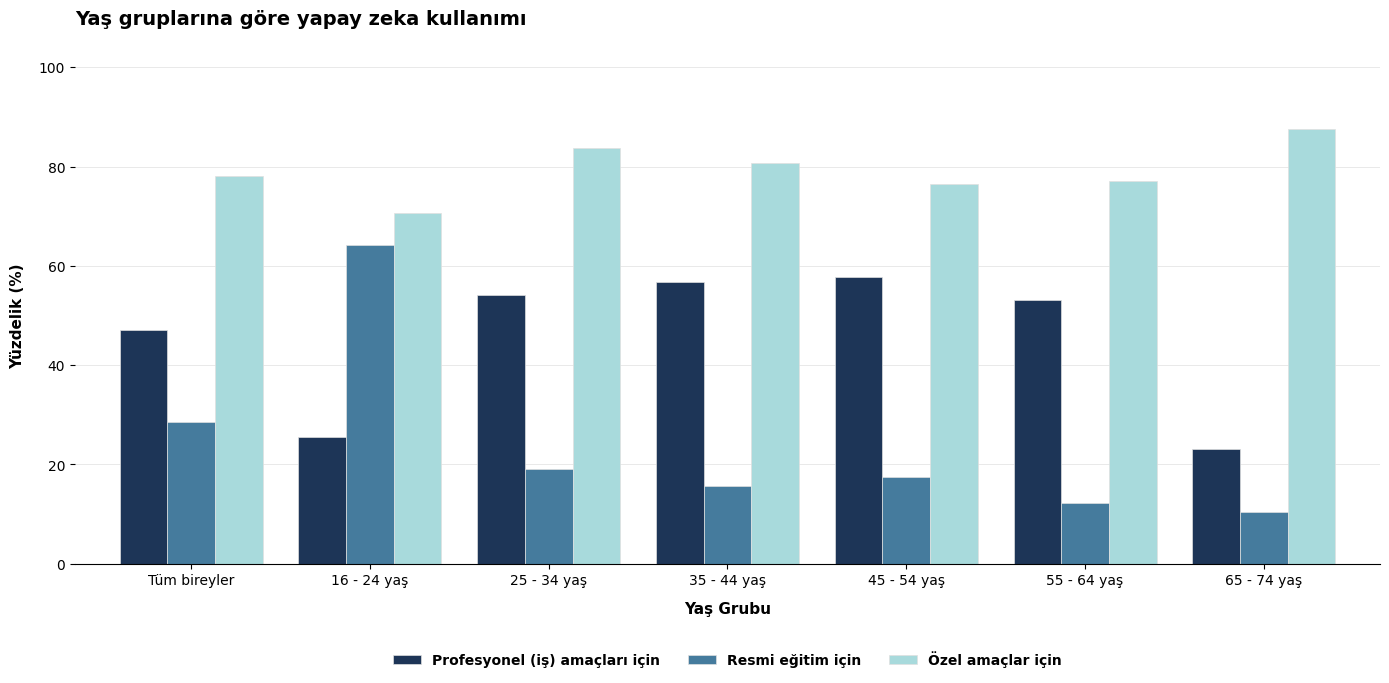

,metrik,deger
0,Gençlerde (16-24 yaş) Eğitim amaçlı kullanım oranı (%),64.22
1,Özel amaçlı en yüksek kullanım oranı (%),87.46
2,Gençlerde (16-24 yaş) iş amaçlı kullanım oranı (%),25.51
3,Gençlerde (16-24 yaş) özel amaçlı kullanım oranı (%),70.60
4,Gençlerde (16-24 yaş) üç amacın ortalama kullanım oranı (%),53.44


In [ ]:
# Yaş gruplarına göre yapay zeka kullanımını ve amacını grafiğe dökülmesine yarayan kod

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

csv_path = Path("isoc_ai_iaiu__custom_20601341_linear.csv")

if csv_path.exists():
    df_raw = pd.read_csv(csv_path)
else:
    raise FileNotFoundError("isoc_ai_iaiu__custom_20601341_linear.csv dosyası bulunamadı")

# Boş ve eksik satırları temizleme
df_clean = df_raw.dropna(subset=['ind_type', 'indic_is', 'OBS_VALUE']).copy()

# Yaş grupları ve göstergeler için temiz etiketler
df_clean['ind_type_clean'] = df_clean['ind_type'].str.strip().str.replace('Individuals, ', '')
df_clean['indic_is_clean'] = df_clean['indic_is'].str.strip().str.replace('Use of generative AI tools: ', '')

# İngilizce yaş gruplarını Türkçe karşılıklarına çevirmek için sözlük tanımlıyoruz
age_translation = {
    'All individuals': 'Tüm bireyler',
    '16 to 24 years old': '16 - 24 yaş',
    '25 to 34 years old': '25 - 34 yaş',
    '35 to 44 years old': '35 - 44 yaş',
    '45 to 54 years old': '45 - 54 yaş',
    '55 to 64 years old': '55 - 64 yaş',
    '65 to 74 years old': '65 - 74 yaş'
}

# Yaş gruplarını Türkçe isimleriyle değiştiriyoruz
df_clean['ind_type_clean'] = df_clean['ind_type_clean'].map(age_translation)

# Türkçe yaş grupları sıralaması
age_order_tr = [
    'Tüm bireyler',
    '16 - 24 yaş',
    '25 - 34 yaş',
    '35 - 44 yaş',
    '45 - 54 yaş',
    '55 - 64 yaş',
    '65 - 74 yaş'
]

# Türkçe sütun isimleri için gösterge çeviri sözlüğü
indic_translation = {
    'for formal education': 'Resmi eğitim için',
    'for private purposes': 'Özel amaçlar için',
    'for professional (work) purposes': 'Profesyonel (iş) amaçları için'
}

df_clean['indic_is_clean'] = df_clean['indic_is_clean'].map(indic_translation)

# CSV dosyasındaki her grup için en son satırdaki değeri filtreleyip alıyoruz
pivot_df = df_clean.pivot_table(
    index='ind_type_clean',
    columns='indic_is_clean',
    values='OBS_VALUE',
    aggfunc='last'
).reindex(age_order_tr)

# Resmi ve Kurumsal (Formal) Renk Paleti
# Lacivert (Deep Navy), Çelik Mavisi (Steel Blue) ve Sıcak Gri (Warm Gray/Charcoal)
formal_colors = ['#1D3557', '#457B9D', '#A8DADC']

# Grafik boyutu ve tasarımı
fig, ax = plt.subplots(figsize=(14, 7), dpi=100)
pivot_df.plot(kind='bar', ax=ax, color=formal_colors, width=0.8, edgecolor='#e0e0e0', linewidth=0.5)

# Başlıklar
plt.title(
    'Yaş gruplarına göre yapay zeka kullanımı \n',
    fontsize=14, fontweight='bold', loc='left', pad=15
)
plt.xlabel('Yaş Grubu', fontsize=11, fontweight='bold', labelpad=10)
plt.ylabel('Yüzdelik (%)', fontsize=11, fontweight='bold', labelpad=10)
plt.xticks(rotation=0)
plt.ylim(0, 100)

# Izgara ve arka plan
plt.grid(axis='y', linestyle='-', linewidth=0.5, color='#e0e0e0')
plt.gca().set_axisbelow(True)



# Açıklama (Legend)
plt.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, -0.15),
    ncol=3,
    frameon=False,
    prop={'weight': 'bold', 'size': 10}
)

# Sadeleştirilmiş kenarlıklar
for spine in ['top', 'right', 'left']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

# Çıktı klasörünü oluşturma ve gerçek verilere göre özet üretme
cikti = Path("sonuclar")
cikti.mkdir(exist_ok=True)

# Türkçe sütun isimlerini kullanarak özet DataFrame oluşturuyoruz
ozet = pd.DataFrame([
    {
        "metrik": "Gençlerde (16-24 yaş) Eğitim amaçlı kullanım oranı (%)",
        "deger": pivot_df.loc["16 - 24 yaş", "Resmi eğitim için"]
    },
    {
        "metrik": "Özel amaçlı en yüksek kullanım oranı (%)",
        "deger": pivot_df["Özel amaçlar için"].max()
    },
    {
        "metrik": "Gençlerde (16-24 yaş) iş amaçlı kullanım oranı (%)",
        "deger": pivot_df.loc["16 - 24 yaş", "Profesyonel (iş) amaçları için"]
    },
    {
        "metrik": "Gençlerde (16-24 yaş) özel amaçlı kullanım oranı (%)",
        "deger": pivot_df.loc["16 - 24 yaş", "Özel amaçlar için"]
    },
    {
    "metrik": "Gençlerde (16-24 yaş) üç amacın ortalama kullanım oranı (%)",
        "deger": round(pivot_df.loc["16 - 24 yaş"].mean(), 2)
    },

])

ozet.to_csv(cikti/"ozet.csv", index=False, encoding="utf-8-sig")
ozet.to_json(cikti/"ozet.json", orient="records", indent=2, force_ascii=False)

# Özeti ekranda gösterelim
pd.set_option('display.max_colwidth', None)

display(ozet)

## Yorum
Eurostat'ın 'isoc_ai_iaiu' kodlu veri setinden elde edilen 2025 yılı verileri, üretken yapay zekâ araçlarının özel, mesleki ve örgün eğitim amaçlı kullanım oranlarını yaş gruplarına göre incelemektedir. Veriler yüzde (%) cinsinden ifade edilmiştir. Grafiğe göre özel amaçlı kullanım tüm yaş gruplarında en yüksek orana sahiptir. 16-24 yaş grubunda örgün eğitim amaçlı kullanım öne çıkarken iş amaçlı kullanım 25-34 ve 35-44 yaş gruplarında daha yaygındır. 65-74 yaş grubunda ise özel amaçlı kullanım en yüksek seviyesine ulaşmıştır. Bununla birlikte veriler yalnızca son üç ay içerisindeki kullanımı kapsamakta; kullanım sıklığı, süresi, kullanılan araçların türü veya verimliliğe etkisi hakkında bilgi vermemektedir.
